In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast

Mounted at /content/drive


In [2]:
MASTER_PATH = "/content/drive/MyDrive/thesis_movie_project/processed/thesis_master.csv"

master = pd.read_csv(MASTER_PATH, low_memory=False)

print("Shape:", master.shape)
master.head()

Shape: (45430, 22)


,id,movieId,imdb_id,title,overview,keywords_clean,cast_clean,director_name,genres_clean,original_language,...,budget,revenue,roi_raw,runtime,popularity,vote_average,vote_count,text_overview_only,text_semantic_enriched,text_semantic_full
0,2,4470,tt0094675,Ariel,Taisto Kasurinen is a Finnish coal miner whose...,underdog prison factory worker prisoner helsin...,Turo Pajala Susanna Haavisto Matti Pellonpää E...,Aki Kaurismäki,Drama Crime,fi,...,NaN,0.0,NaN,69.0,3.860491,7.1,44.0,Taisto Kasurinen is a Finnish coal miner whose...,Ariel underdog prison factory worker prisoner ...,Ariel underdog prison factory worker prisoner ...
1,3,61724,tt0092149,Shadows in Paradise,"An episode in the life of Nikander, a garbage ...",salesclerk helsinki garbage independent film,Matti Pellonpää Kati Outinen Sakari Kuosmanen ...,Aki Kaurismäki,Drama Comedy,fi,...,NaN,0.0,NaN,76.0,2.292110,7.1,35.0,"An episode in the life of Nikander, a garbage ...",Shadows in Paradise salesclerk helsinki garbag...,Shadows in Paradise salesclerk helsinki garbag...
2,5,18,tt0113101,Four Rooms,It's Ted the Bellhop's first night on the job....,hotel new year's eve witch bet hotel room sper...,Tim Roth Antonio Banderas Jennifer Beals Madon...,Allison Anders,Crime Comedy,en,...,4000000.0,4300000.0,1.075000,98.0,9.026586,6.5,539.0,It's Ted the Bellhop's first night on the job....,Four Rooms hotel new year's eve witch bet hote...,Four Rooms hotel new year's eve witch bet hote...
3,6,479,tt0107286,Judgment Night,"While racing to a boxing match, Frank, Mike, J...",chicago drug dealer boxing match escape one night,Emilio Estevez Cuba Gooding Jr. Denis Leary Je...,Stephen Hopkins,Action Thriller Crime,en,...,NaN,12136938.0,NaN,110.0,5.538671,6.4,79.0,"While racing to a boxing match, Frank, Mike, J...",Judgment Night chicago drug dealer boxing matc...,Judgment Night chicago drug dealer boxing matc...
4,11,260,tt0076759,Star Wars,Princess Leia is captured and held hostage by ...,android galaxy hermit death star lightsaber je...,Mark Hamill Harrison Ford Carrie Fisher Peter ...,George Lucas,Adventure Action Science Fiction,en,...,11000000.0,775398007.0,70.490728,121.0,42.149697,8.1,6778.0,Princess Leia is captured and held hostage by ...,Star Wars android galaxy hermit death star lig...,Star Wars android galaxy hermit death star lig...


In [3]:
print("Columns:\n")
for col in master.columns:
    print("-", col)

print("\nData types:\n")
print(master.dtypes)

print("\nMissing values (%):\n")
print((master.isna().mean() * 100).round(2).sort_values(ascending=False))

Columns:

- id
- movieId
- imdb_id
- title
- overview
- keywords_clean
- cast_clean
- director_name
- genres_clean
- original_language
- release_date
- release_year
- budget
- revenue
- roi_raw
- runtime
- popularity
- vote_average
- vote_count
- text_overview_only
- text_semantic_enriched
- text_semantic_full

Data types:

id                          int64
movieId                     int64
imdb_id                    object
title                      object
overview                   object
keywords_clean             object
cast_clean                 object
director_name              object
genres_clean               object
original_language          object
release_date               object
release_year              float64
budget                    float64
revenue                   float64
roi_raw                   float64
runtime                   float64
popularity                float64
vote_average              float64
vote_count                float64
text_overview_only         o

In [4]:
print("Duplicate id rows:", master["id"].duplicated().sum())

if "movieId" in master.columns:
    print("Duplicate movieId rows (ignoring NaN):", master["movieId"].dropna().duplicated().sum())

print("Unique id count:", master["id"].nunique())
print("Total rows:", len(master))

Duplicate id rows: 0
Duplicate movieId rows (ignoring NaN): 0
Unique id count: 45430
Total rows: 45430


In [5]:
# Text lengths
master["overview_len"] = master["overview"].fillna("").astype(str).str.len()
master["title_len"] = master["title"].fillna("").astype(str).str.len()
master["keywords_len"] = master["keywords_clean"].fillna("").astype(str).str.len()
master["cast_len"] = master["cast_clean"].fillna("").astype(str).str.len()

# Token counts (rough)
master["overview_word_count"] = master["overview"].fillna("").astype(str).str.split().str.len()
master["keywords_word_count"] = master["keywords_clean"].fillna("").astype(str).str.split().str.len()
master["cast_word_count"] = master["cast_clean"].fillna("").astype(str).str.split().str.len()

# Finance cleaning for analysis
master["budget_clean"] = pd.to_numeric(master["budget"], errors="coerce")
master["revenue_clean"] = pd.to_numeric(master["revenue"], errors="coerce")

master.loc[master["budget_clean"] <= 0, "budget_clean"] = np.nan
master.loc[master["revenue_clean"] <= 0, "revenue_clean"] = np.nan

master["roi_clean"] = np.where(
    master["budget_clean"].notna() & master["revenue_clean"].notna(),
    master["revenue_clean"] / master["budget_clean"],
    np.nan
)

print("Helper columns created.")

Helper columns created.


In [6]:
validation_summary = {
    "rows": len(master),
    "unique_ids": master["id"].nunique(),
    "duplicate_ids": master["id"].duplicated().sum(),
    "empty_title_pct": (master["title_len"] == 0).mean() * 100,
    "empty_overview_pct": (master["overview_len"] == 0).mean() * 100,
    "very_short_overview_pct (<20 chars)": (master["overview_len"] < 20).mean() * 100,
    "empty_keywords_pct": (master["keywords_len"] == 0).mean() * 100,
    "empty_cast_pct": (master["cast_len"] == 0).mean() * 100,
    "missing_release_year_pct": master["release_year"].isna().mean() * 100,
    "valid_budget_pct": master["budget_clean"].notna().mean() * 100,
    "valid_revenue_pct": master["revenue_clean"].notna().mean() * 100,
    "valid_roi_pct": master["roi_clean"].notna().mean() * 100,
}

for k, v in validation_summary.items():
    if isinstance(v, float):
        print(f"{k}: {v:.2f}")
    else:
        print(f"{k}: {v}")

rows: 45430
unique_ids: 45430
duplicate_ids: 0
empty_title_pct: 0.00
empty_overview_pct: 2.11
very_short_overview_pct (<20 chars): 2.51
empty_keywords_pct: 31.57
empty_cast_pct: 5.32
missing_release_year_pct: 0.18
valid_budget_pct: 19.55
valid_revenue_pct: 16.28
valid_roi_pct: 11.83


In [7]:
print("Release year summary:")
print(master["release_year"].describe())

print("\nEarliest years:")
print(master["release_year"].dropna().sort_values().head(20).tolist())

print("\nLatest years:")
print(master["release_year"].dropna().sort_values(ascending=False).head(20).tolist())

Release year summary:
count    45346.000000
mean      1991.882834
std         24.053040
min       1874.000000
25%       1978.000000
50%       2001.000000
75%       2010.000000
max       2020.000000
Name: release_year, dtype: float64

Earliest years:
[1874.0, 1878.0, 1883.0, 1887.0, 1888.0, 1888.0, 1890.0, 1890.0, 1890.0, 1890.0, 1890.0, 1891.0, 1891.0, 1891.0, 1891.0, 1891.0, 1891.0, 1892.0, 1892.0, 1892.0]

Latest years:
[2020.0, 2018.0, 2018.0, 2018.0, 2018.0, 2018.0, 2017.0, 2017.0, 2017.0, 2017.0, 2017.0, 2017.0, 2017.0, 2017.0, 2017.0, 2017.0, 2017.0, 2017.0, 2017.0, 2017.0]


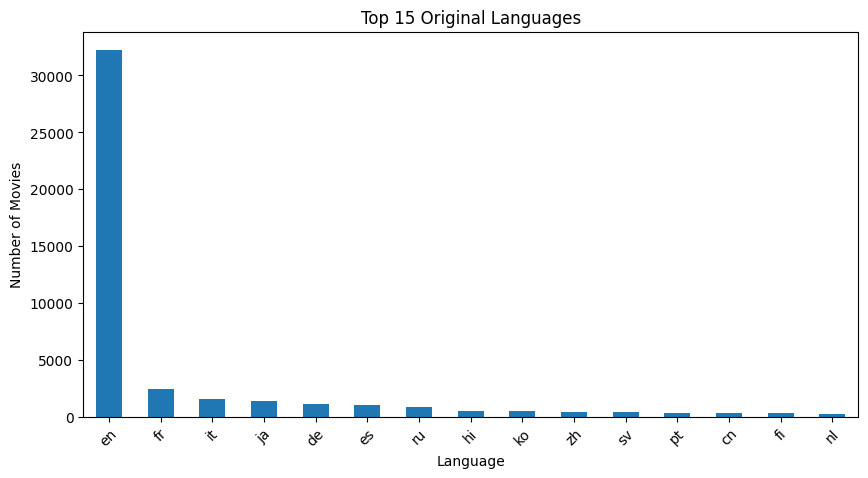

In [8]:
lang_counts = master["original_language"].fillna("").replace("", "UNKNOWN").value_counts().head(15)

plt.figure(figsize=(10,5))
lang_counts.plot(kind="bar")
plt.title("Top 15 Original Languages")
plt.ylabel("Number of Movies")
plt.xlabel("Language")
plt.xticks(rotation=45)
plt.show()

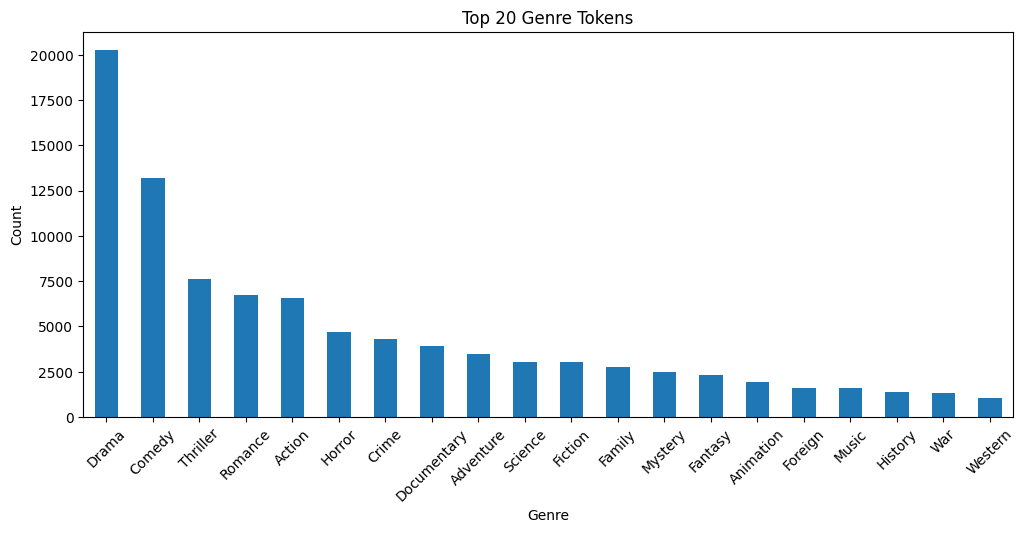

,0
Drama,20243
Comedy,13176
Thriller,7618
Romance,6730
Action,6590
Horror,4670
Crime,4304
Documentary,3930
Adventure,3490
Science,3042


In [9]:
from collections import Counter

genre_counter = Counter()

for row in master["genres_clean"].fillna(""):
    genres = [g.strip() for g in row.split() if g.strip()]
    genre_counter.update(genres)

top_genres = pd.Series(dict(genre_counter)).sort_values(ascending=False).head(20)

plt.figure(figsize=(12,5))
top_genres.plot(kind="bar")
plt.title("Top 20 Genre Tokens")
plt.ylabel("Count")
plt.xlabel("Genre")
plt.xticks(rotation=45)
plt.show()

top_genres

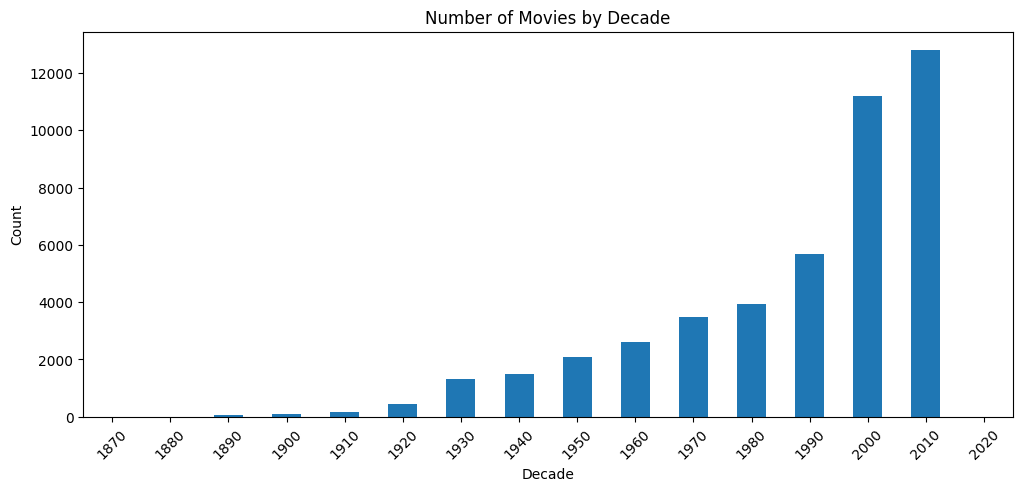

In [10]:
master["decade"] = (master["release_year"] // 10) * 10

decade_counts = master["decade"].dropna().astype(int).value_counts().sort_index()

plt.figure(figsize=(12,5))
decade_counts.plot(kind="bar")
plt.title("Number of Movies by Decade")
plt.ylabel("Count")
plt.xlabel("Decade")
plt.xticks(rotation=45)
plt.show()

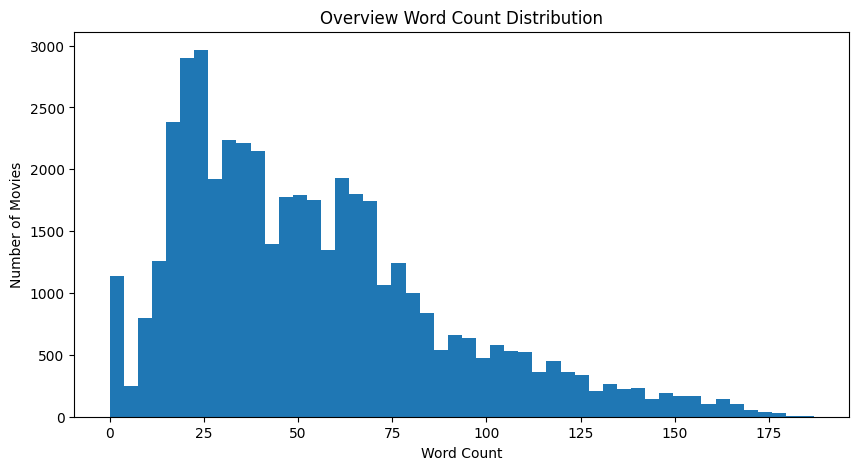

count    45430.000000
mean        53.951376
std         35.408586
min          0.000000
25%         26.000000
50%         47.000000
75%         72.000000
max        187.000000
Name: overview_word_count, dtype: float64


In [11]:
plt.figure(figsize=(10,5))
plt.hist(master["overview_word_count"].dropna(), bins=50)
plt.title("Overview Word Count Distribution")
plt.xlabel("Word Count")
plt.ylabel("Number of Movies")
plt.show()

print(master["overview_word_count"].describe())

In [12]:
short_overviews = master.loc[
    master["overview_word_count"] < 10,
    ["id", "title", "overview", "release_year"]
].head(20)

short_overviews

,id,title,overview,release_year
932,1481,Metal Skin,No overview found.,1994.0
953,1539,Keine Lieder über Liebe,No overview found.,2005.0
1049,1655,Praxis Dr. Hasenbein,No overview found.,1997.0
1051,1659,Texas - Doc Snyder hält die Welt in Atem,No overview found.,1993.0
1198,1896,Salvador (Puig Antich),No overview found.,2006.0
1212,1914,FC Venus,No overview found.,2006.0
1306,2029,Tanguy,No overview found.,2001.0
1373,2132,Totally Blonde,No overview found.,2001.0
1399,2169,Manta - Der Film,No overview found.,1991.0
1410,2192,Temple of the White Elephant,Temple of the White Elephant,1964.0


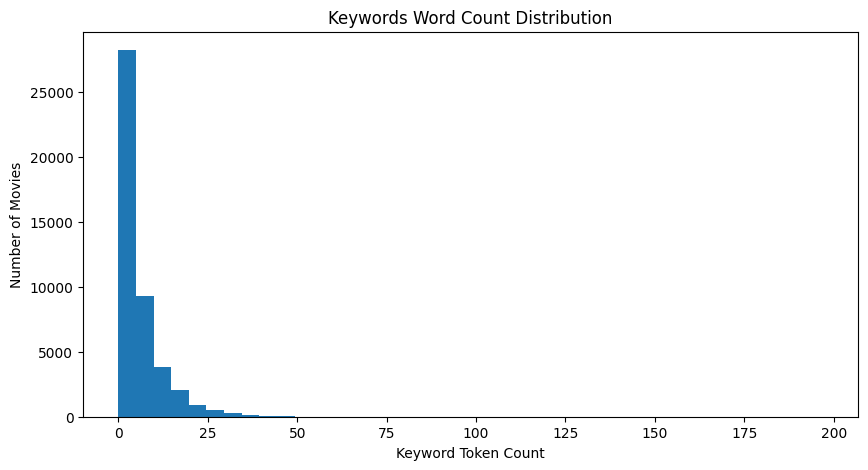

count    45430.000000
mean         5.093396
std          7.062864
min          0.000000
25%          0.000000
50%          3.000000
75%          7.000000
max        197.000000
Name: keywords_word_count, dtype: float64


In [13]:
plt.figure(figsize=(10,5))
plt.hist(master["keywords_word_count"].dropna(), bins=40)
plt.title("Keywords Word Count Distribution")
plt.xlabel("Keyword Token Count")
plt.ylabel("Number of Movies")
plt.show()

print(master["keywords_word_count"].describe())

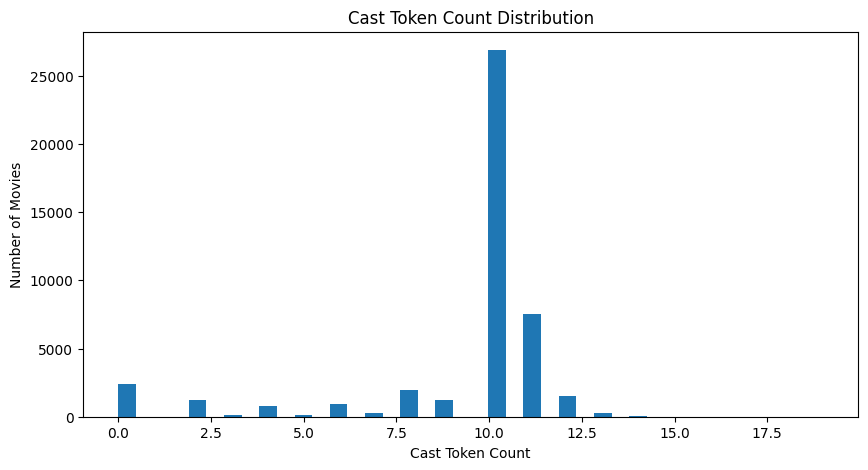

count    45430.000000
mean         9.164121
std          2.857125
min          0.000000
25%         10.000000
50%         10.000000
75%         10.000000
max         19.000000
Name: cast_word_count, dtype: float64


In [14]:
plt.figure(figsize=(10,5))
plt.hist(master["cast_word_count"].dropna(), bins=40)
plt.title("Cast Token Count Distribution")
plt.xlabel("Cast Token Count")
plt.ylabel("Number of Movies")
plt.show()

print(master["cast_word_count"].describe())

In [15]:
finance_summary = {
    "budget > 0": (master["budget_clean"].notna()).sum(),
    "revenue > 0": (master["revenue_clean"].notna()).sum(),
    "valid ROI": (master["roi_clean"].notna()).sum(),
}

finance_summary

{'budget > 0': np.int64(8880),
 'revenue > 0': np.int64(7398),
 'valid ROI': np.int64(5375)}

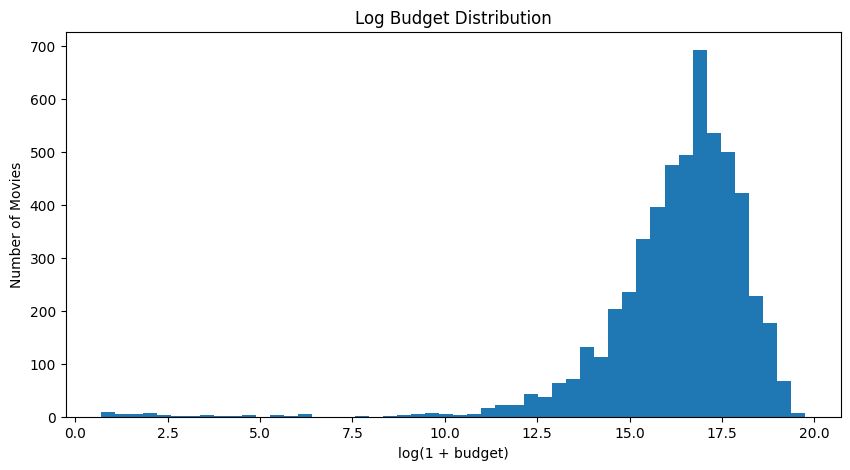

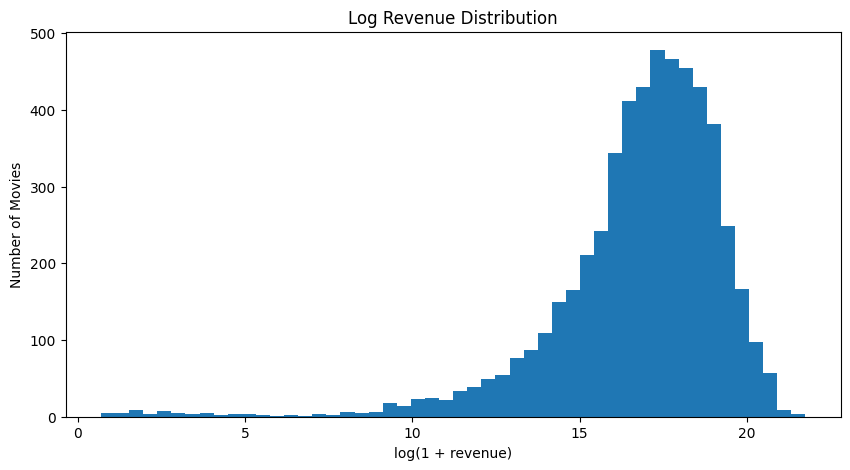

In [16]:
finance_subset = master[
    master["budget_clean"].notna() & master["revenue_clean"].notna()
].copy()

finance_subset["log_budget"] = np.log1p(finance_subset["budget_clean"])
finance_subset["log_revenue"] = np.log1p(finance_subset["revenue_clean"])

plt.figure(figsize=(10,5))
plt.hist(finance_subset["log_budget"], bins=50)
plt.title("Log Budget Distribution")
plt.xlabel("log(1 + budget)")
plt.ylabel("Number of Movies")
plt.show()

plt.figure(figsize=(10,5))
plt.hist(finance_subset["log_revenue"], bins=50)
plt.title("Log Revenue Distribution")
plt.xlabel("log(1 + revenue)")
plt.ylabel("Number of Movies")
plt.show()

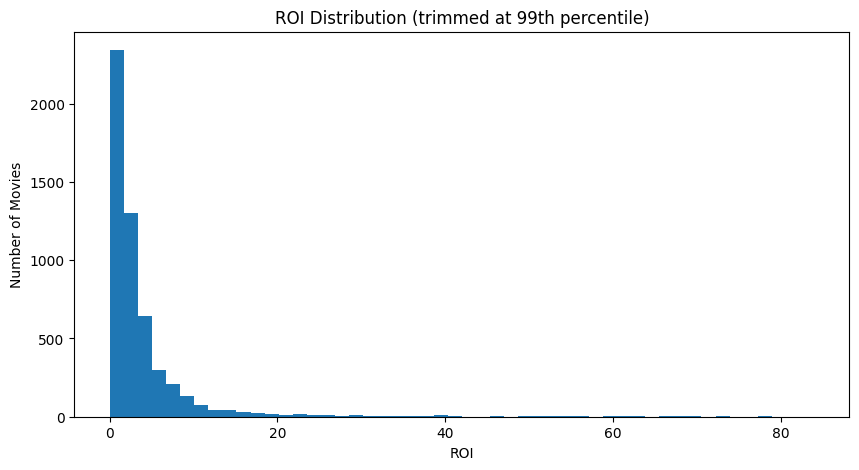

count    5.321000e+03
mean     3.925932e+00
std      7.045987e+00
min      5.217391e-07
25%      7.825000e-01
50%      2.025316e+00
75%      4.143675e+00
max      8.400000e+01
Name: roi_clean, dtype: float64


In [17]:
roi_subset = finance_subset[np.isfinite(finance_subset["roi_clean"])].copy()
roi_subset = roi_subset[roi_subset["roi_clean"] < roi_subset["roi_clean"].quantile(0.99)]

plt.figure(figsize=(10,5))
plt.hist(roi_subset["roi_clean"], bins=50)
plt.title("ROI Distribution (trimmed at 99th percentile)")
plt.xlabel("ROI")
plt.ylabel("Number of Movies")
plt.show()

print(roi_subset["roi_clean"].describe())

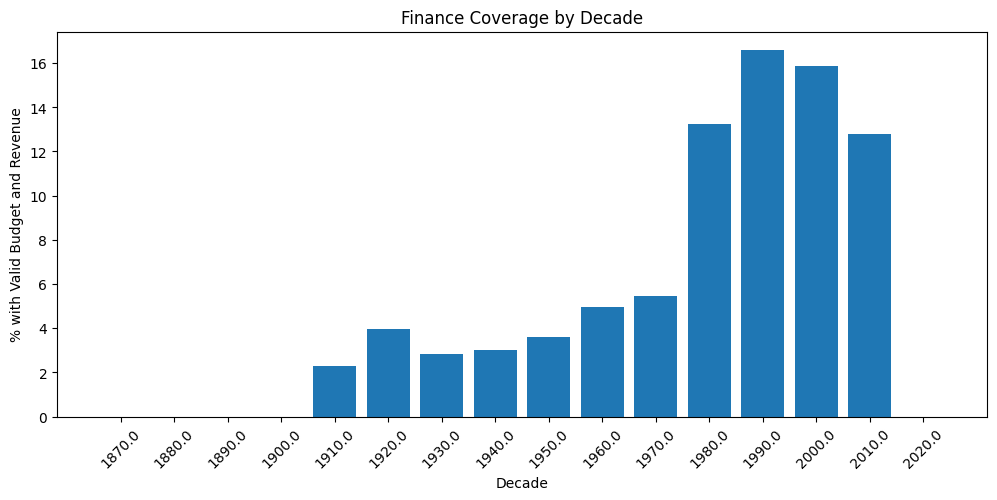

,decade,total_movies,valid_finance,finance_coverage_pct
1,1880.0,4,0,0.000000
2,1890.0,75,0,0.000000
3,1900.0,87,0,0.000000
4,1910.0,176,4,2.272727
5,1920.0,431,17,3.944316
6,1930.0,1315,37,2.813688
7,1940.0,1493,45,3.014066
8,1950.0,2079,75,3.607504
9,1960.0,2621,130,4.959939
10,1970.0,3471,190,5.473927


In [18]:
finance_by_decade = master.groupby("decade").agg(
    total_movies=("id", "size"),
    valid_finance=("roi_clean", lambda x: x.notna().sum())
).reset_index()

finance_by_decade["finance_coverage_pct"] = (
    finance_by_decade["valid_finance"] / finance_by_decade["total_movies"] * 100
)

plt.figure(figsize=(12,5))
plt.bar(finance_by_decade["decade"].astype(str), finance_by_decade["finance_coverage_pct"])
plt.title("Finance Coverage by Decade")
plt.ylabel("% with Valid Budget and Revenue")
plt.xlabel("Decade")
plt.xticks(rotation=45)
plt.show()

finance_by_decade.tail(15)

In [19]:
# Main semantic dataset
df_semantic = master[
    master["overview"].fillna("").astype(str).str.strip().str.len() > 0
].copy()

# Representation comparison dataset
df_network_compare = df_semantic.copy()

# Strict finance dataset
df_finance = master[
    (master["overview"].fillna("").astype(str).str.strip().str.len() > 0) &
    (master["budget_clean"].notna()) &
    (master["revenue_clean"].notna())
].copy()

df_finance["log_budget"] = np.log1p(df_finance["budget_clean"])
df_finance["log_revenue"] = np.log1p(df_finance["revenue_clean"])

print("df_semantic shape:", df_semantic.shape)
print("df_network_compare shape:", df_network_compare.shape)
print("df_finance shape:", df_finance.shape)

df_semantic shape: (44471, 33)
df_network_compare shape: (44471, 33)
df_finance shape: (5364, 35)


In [ ]:
import pandas as pd
import numpy as np

V3_PATH = "/content/drive/MyDrive/thesis_movie_project/processed/thesis_master_v3.csv"
master = pd.read_csv(V3_PATH, low_memory=False)

# --------------------------------------------------
# Helper columns
# --------------------------------------------------
master["overview_len"] = master["overview"].fillna("").astype(str).str.len()
master["overview_word_count"] = master["overview"].fillna("").astype(str).str.split().str.len()

master["budget_clean"] = pd.to_numeric(master["budget"], errors="coerce")
master["revenue_clean"] = pd.to_numeric(master["revenue"], errors="coerce")

master.loc[master["budget_clean"] <= 0, "budget_clean"] = np.nan
master.loc[master["revenue_clean"] <= 0, "revenue_clean"] = np.nan

master["roi_clean"] = np.where(
    master["budget_clean"].notna() & master["revenue_clean"].notna(),
    master["revenue_clean"] / master["budget_clean"],
    np.nan
)

# --------------------------------------------------
# 1. MAIN SEMANTIC CORE DATASET
# --------------------------------------------------
df_semantic_core = master[
    (master["overview_len"] > 30) &
    (master["runtime"].fillna(0) >= 60) &
    (master["release_year"].notna())
].copy()

# --------------------------------------------------
# 2. REPRESENTATION COMPARISON DATASET
# --------------------------------------------------
df_network_compare = df_semantic_core.copy()

# --------------------------------------------------
# 3. REVENUE VALIDATION DATASET
# --------------------------------------------------
df_revenue = df_semantic_core[
    df_semantic_core["revenue_clean"].notna()
].copy()

df_revenue["log_revenue"] = np.log1p(df_revenue["revenue_clean"])

# --------------------------------------------------
# 4. ROI VALIDATION DATASET
# --------------------------------------------------
df_roi = df_semantic_core[
    df_semantic_core["budget_clean"].notna() &
    df_semantic_core["revenue_clean"].notna()
].copy()

df_roi["log_budget"] = np.log1p(df_roi["budget_clean"])
df_roi["log_revenue"] = np.log1p(df_roi["revenue_clean"])

print("df_semantic_core:", df_semantic_core.shape)
print("df_network_compare:", df_network_compare.shape)
print("df_revenue:", df_revenue.shape)
print("df_roi:", df_roi.shape)

# Save them
SAVE_DIR = "/content/drive/MyDrive/thesis_movie_project/processed"
df_semantic_core.to_csv(f"{SAVE_DIR}/df_semantic_core_v3.csv", index=False)
df_network_compare.to_csv(f"{SAVE_DIR}/df_network_compare_v3.csv", index=False)
df_revenue.to_csv(f"{SAVE_DIR}/df_revenue_v3.csv", index=False)
df_roi.to_csv(f"{SAVE_DIR}/df_roi_v3.csv", index=False)

print("\nSaved:")
print("- df_semantic_core_v3.csv")
print("- df_network_compare_v3.csv")
print("- df_revenue_v3.csv")
print("- df_roi_v3.csv")